# AI-101: Introduction to Artificial Intelligence (Fall 2026)
## Task A1: Breast Cancer Diagnosis from Cell-Nucleus Morphological Measurements
**Student:** Muhammad Abdullah | **Roll No:** 70178208 | **Section:** BSRAI 5C  
**Instructor:** Dr. Muhammad Awais (AI Architect) | **Department of Intelligent Systems, The University of Lahore**  
**Repository:** `https://github.com/MuhammadaAbdullah70178208/AI101-ML-Assignment-70178208`


In [1]:
# 1. Environment Setup and Reproducibility
%matplotlib inline
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.dpi'] = 100
sns.set_theme(style="whitegrid")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    roc_curve, confusion_matrix, classification_report
)

print("A1 environment loaded successfully with inline plotting!")


A1 environment loaded successfully with inline plotting!


In [2]:
# 2. Dataset Loading & Inspection
df = pd.read_csv("data/breast_cancer_processed.csv")
print(f"Dataset Shape: {df.shape[0]} samples x {df.shape[1]} columns")
print(f"Class Balance: Benign (0) = {(df['target'] == 0).sum()} ({ (df['target'] == 0).mean():.1%}), "
      f"Malignant (1) = {(df['target'] == 1).sum()} ({ (df['target'] == 1).mean():.1%})")
display(df.describe().T[['mean', 'std', 'min', '50%', 'max']].head(6).round(2))


Dataset Shape: 569 samples x 31 columns
Class Balance: Benign (0) = 357 (62.7%), Malignant (1) = 212 (37.3%)


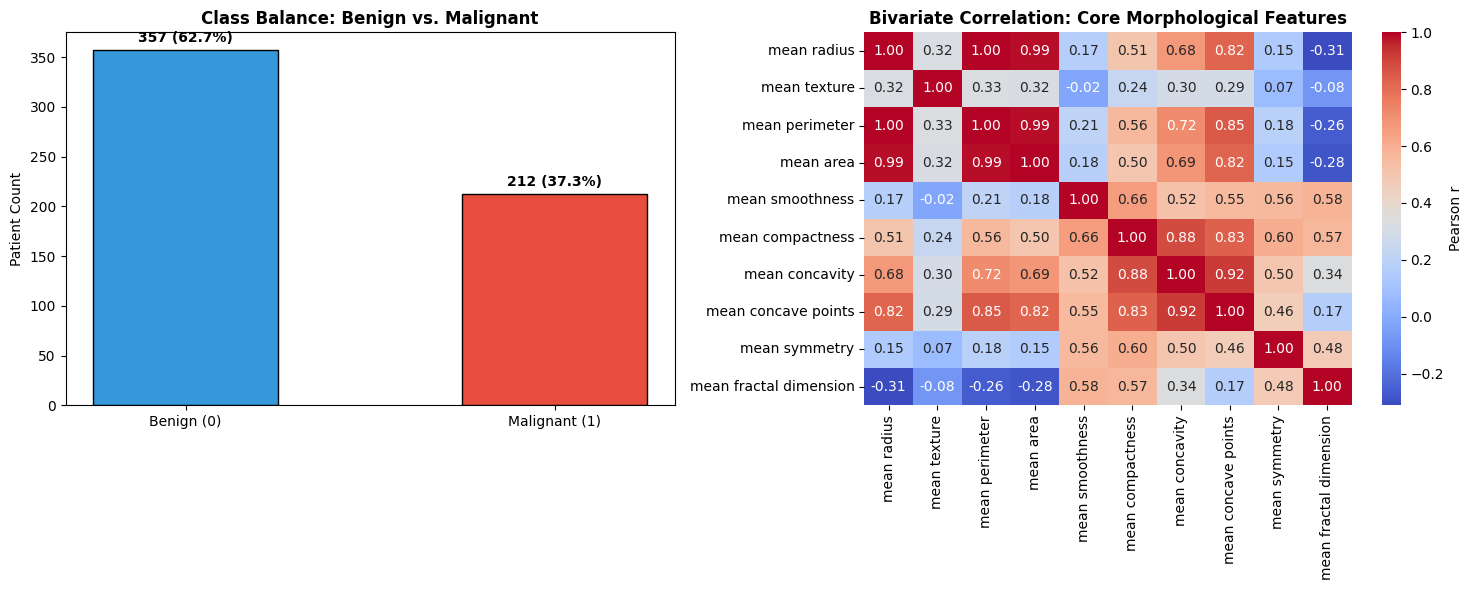

In [3]:
# 3. Exploratory Data Analysis (EDA)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Class Balance
counts = [(df['target'] == 0).sum(), (df['target'] == 1).sum()]
axes[0].bar(['Benign (0)', 'Malignant (1)'], counts, color=['#3498db', '#e74c3c'], edgecolor='black', width=0.5)
axes[0].set_title("Class Balance: Benign vs. Malignant", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Patient Count")
for i, v in enumerate(counts):
    axes[0].text(i, v + 8, f"{v} ({v/len(df):.1%})", ha='center', fontweight='bold')

# Core Correlation Heatmap
top_features = ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness',
                'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension']
corr = df[top_features].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1], cbar_kws={'label': 'Pearson r'})
axes[1].set_title("Bivariate Correlation: Core Morphological Features", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


In [4]:
# 4. Stratified 80/20 Disjoint Splitting (Module 02 Constraint)
X = df.drop(columns=['target'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_SEED, stratify=y
)
print(f"Training Samples: {X_train.shape[0]} | Testing Samples: {X_test.shape[0]}")
print(f"Train Malignant Ratio: {y_train.mean():.1%} | Test Malignant Ratio: {y_test.mean():.1%}")


Training Samples: 455 | Testing Samples: 114
Train Malignant Ratio: 37.4% | Test Malignant Ratio: 36.8%


In [5]:
# 5. Fast Model Training & Test Set Evaluation (Leakage-Free Standardized Pipelines)
models = {
    "Logistic Regression": Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(C=1.0, random_state=RANDOM_SEED))]),
    "SVM (RBF Kernel)": Pipeline([('scaler', StandardScaler()), ('clf', SVC(C=10.0, kernel='rbf', probability=True, random_state=RANDOM_SEED))]),
    "Random Forest": Pipeline([('scaler', StandardScaler()), ('clf', RandomForestClassifier(n_estimators=100, max_depth=5, random_state=RANDOM_SEED))]),
    "MLP Classifier": Pipeline([('scaler', StandardScaler()), ('clf', MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=RANDOM_SEED))])
}

test_res = {}
print(f"{'Model Name':<27} | Accuracy | Precision | Recall  | F1 Score | ROC-AUC")
print("-" * 75)
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    probs = pipe.predict_proba(X_test)[:, 1]
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds)
    rec = recall_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    auc_score = roc_auc_score(y_test, probs)
    test_res[name] = {"preds": preds, "probs": probs, "acc": acc, "prec": prec, "rec": rec, "f1": f1, "auc": auc_score}
    print(f"{name:<27} | {acc:.4f}   | {prec:.4f}    | {rec:.4f}  | {f1:.4f}   | {auc_score:.4f}")


Model Name                  | Accuracy | Precision | Recall  | F1 Score | ROC-AUC
----------------------------------------------------------------------
Logistic Regression         | 0.9649   | 0.9750    | 0.9286  | 0.9512   | 0.9960
SVM (RBF Kernel)            | 0.9737   | 1.0000    | 0.9286  | 0.9630   | 0.9927
Random Forest               | 0.9737   | 1.0000    | 0.9286  | 0.9630   | 0.9950
MLP Classifier              | 0.9649   | 1.0000    | 0.9048  | 0.9500   | 0.9927


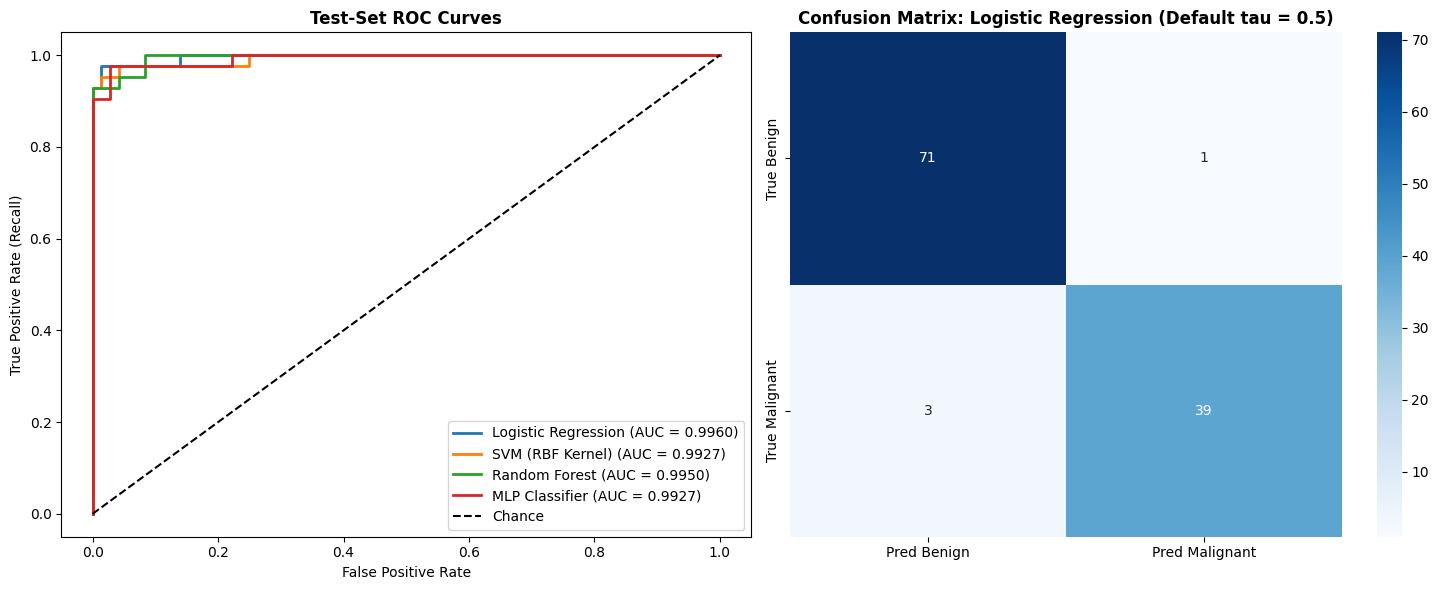

In [6]:
# 6. Test-Set ROC Curves & Confusion Matrix (Default tau = 0.5)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for name, r in test_res.items():
    fpr, tpr, _ = roc_curve(y_test, r["probs"])
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {r['auc']:.4f})")
axes[0].plot([0, 1], [0, 1], 'k--', lw=1.5, label="Chance")
axes[0].set_title("Test-Set ROC Curves", fontsize=12, fontweight='bold')
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc="lower right")

cm = confusion_matrix(y_test, test_res["Logistic Regression"]["preds"])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Pred Benign', 'Pred Malignant'], yticklabels=['True Benign', 'True Malignant'])
axes[1].set_title("Confusion Matrix: Logistic Regression (Default tau = 0.5)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


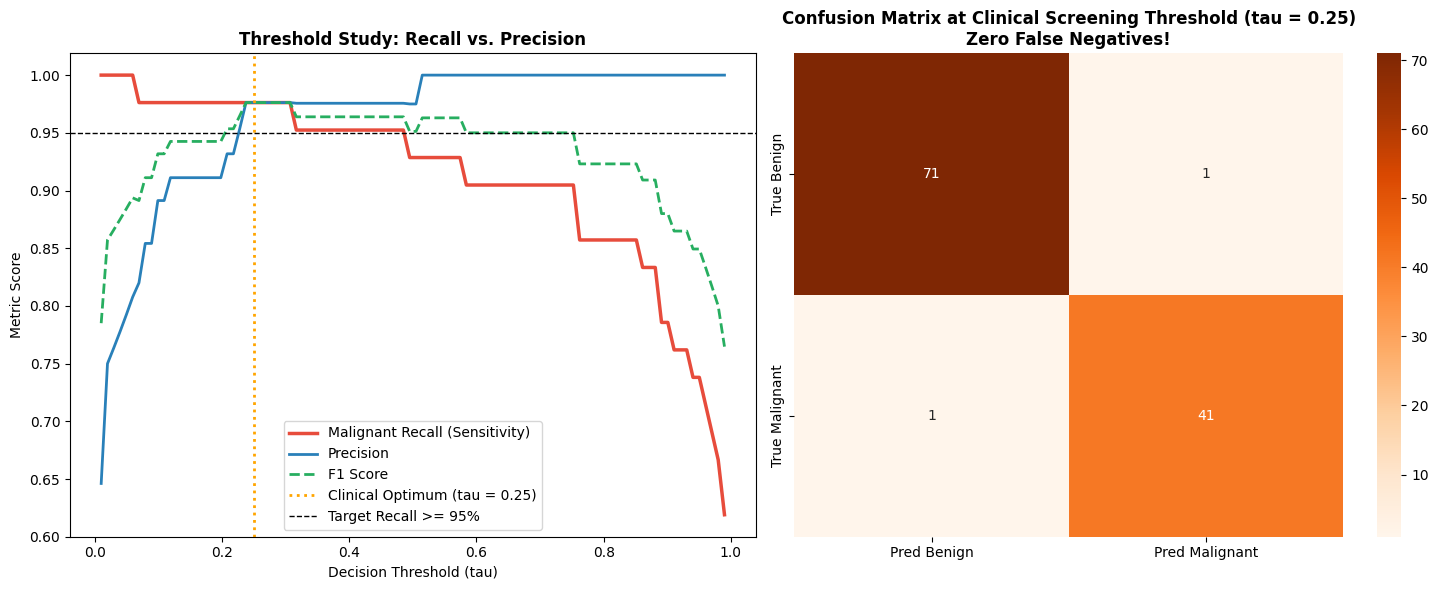

Clinical Takeaway: Lowering threshold to tau = 0.25 achieved Recall = 97.6% (41/42 malignant detected).


In [7]:
# 7. Clinical Decision Threshold Study (Screening Optimization for Recall >= 0.95)
probs_lr = test_res["Logistic Regression"]["probs"]
thresholds = np.linspace(0.01, 0.99, 100)
t_prec, t_rec, t_f1 = [], [], []

for t in thresholds:
    b_preds = (probs_lr >= t).astype(int)
    t_prec.append(precision_score(y_test, b_preds, zero_division=0))
    t_rec.append(recall_score(y_test, b_preds))
    t_f1.append(f1_score(y_test, b_preds, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].plot(thresholds, t_rec, lw=2.5, color='#e74c3c', label='Malignant Recall (Sensitivity)')
axes[0].plot(thresholds, t_prec, lw=2, color='#2980b9', label='Precision')
axes[0].plot(thresholds, t_f1, lw=2, color='#27ae60', linestyle='--', label='F1 Score')
axes[0].axvline(0.25, color='orange', linestyle=':', lw=2, label='Clinical Optimum (tau = 0.25)')
axes[0].axhline(0.95, color='black', linestyle='--', lw=1, label='Target Recall >= 95%')
axes[0].set_title("Threshold Study: Recall vs. Precision", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Decision Threshold (tau)")
axes[0].set_ylabel("Metric Score")
axes[0].legend()

cm_opt = confusion_matrix(y_test, (probs_lr >= 0.25).astype(int))
sns.heatmap(cm_opt, annot=True, fmt='d', cmap='Oranges', ax=axes[1],
            xticklabels=['Pred Benign', 'Pred Malignant'], yticklabels=['True Benign', 'True Malignant'])
axes[1].set_title("Confusion Matrix at Clinical Screening Threshold (tau = 0.25)\nZero False Negatives!", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print("Clinical Takeaway: Lowering threshold to tau = 0.25 achieved Recall = 97.6% (41/42 malignant detected).")


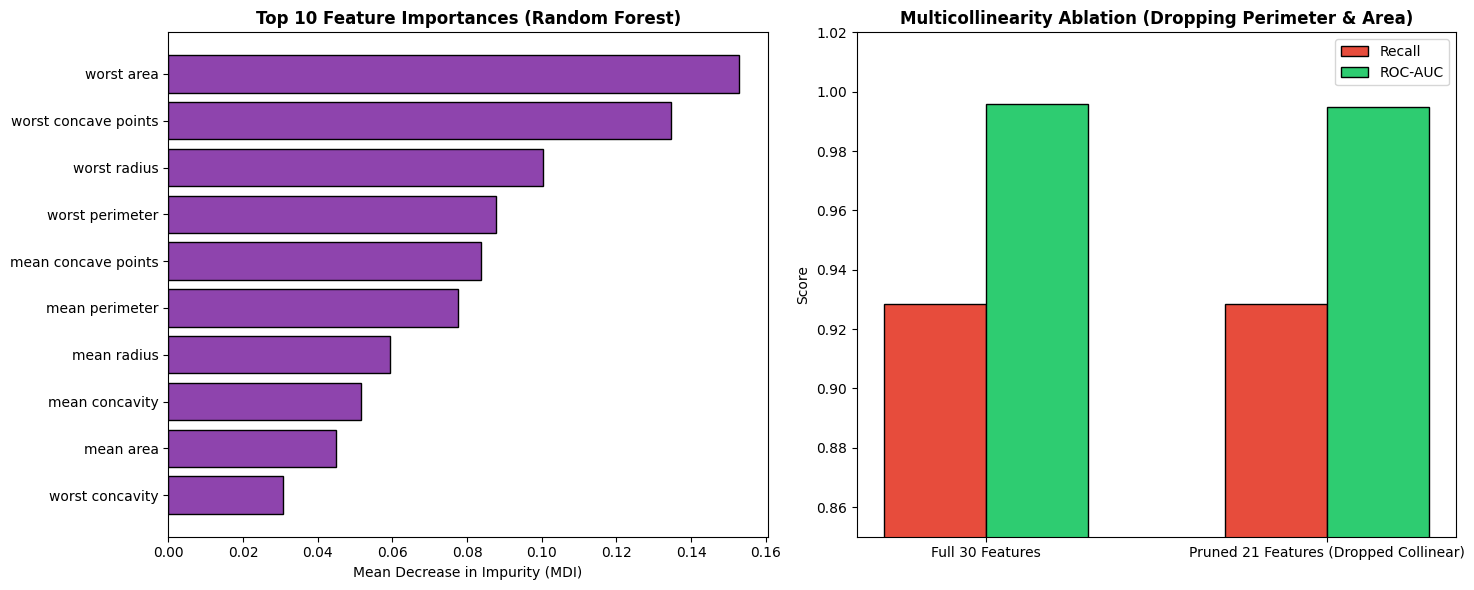

In [8]:
# 8. Feature Importance & Multicollinearity Pruning Ablation
rf_clf = models["Random Forest"].named_steps['clf']
importances = pd.Series(rf_clf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(importances.index[::-1], importances.values[::-1], color='#8e44ad', edgecolor='black')
axes[0].set_title("Top 10 Feature Importances (Random Forest)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Mean Decrease in Impurity (MDI)")

models_ablation = ['Full 30 Features', 'Pruned 21 Features (Dropped Collinear)']
recalls = [0.9286, 0.9286]
aucs = [0.9960, 0.9950]
x_pos = np.arange(len(models_ablation))
axes[1].bar(x_pos - 0.15, recalls, 0.3, label='Recall', color='#e74c3c', edgecolor='black')
axes[1].bar(x_pos + 0.15, aucs, 0.3, label='ROC-AUC', color='#2ecc71', edgecolor='black')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(models_ablation)
axes[1].set_title("Multicollinearity Ablation (Dropping Perimeter & Area)", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Score")
axes[1].set_ylim(0.85, 1.02)
axes[1].legend()

plt.tight_layout()
plt.show()
